<a href="https://colab.research.google.com/github/mugalan/vibration-analysis/blob/main/answers-to-selected-assignments/Vehicle_Suspension_Modeling_and_Simulation_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vehicle suspension: modeling, modal analysis, and simulation


**A self-contained, four-degree-of-freedom computational laboratory**  
*Linear heave–pitch dynamics · wheel-hop · road forcing · modes · damping · interactive Plotly demonstrations*



### Learning goals

1. Derive the equations of motion and assemble $M$, $C$, and $K$ without transcription errors.
2. Explain natural frequencies, heave–pitch coupling, and the effect of geometric symmetry.
3. Simulate a vehicle crossing a road bump at finite speed, including the rear-wheel delay.
4. Examine displacement, acceleration, suspension travel, and dynamic tire force.
5. Compare free-decay energy, frequency responses, damping choices, and parameter sensitivity.
6. Visualize the rigid-body motion with an animated Plotly schematic.

**Model fidelity.** The governing equations and coordinates are preserved from the uploaded notebook. Road displacement, optional tire damping, energy checks, frequency-response investigations, and parameter sweeps are **explicit additions**.

## 1. The mechanical system

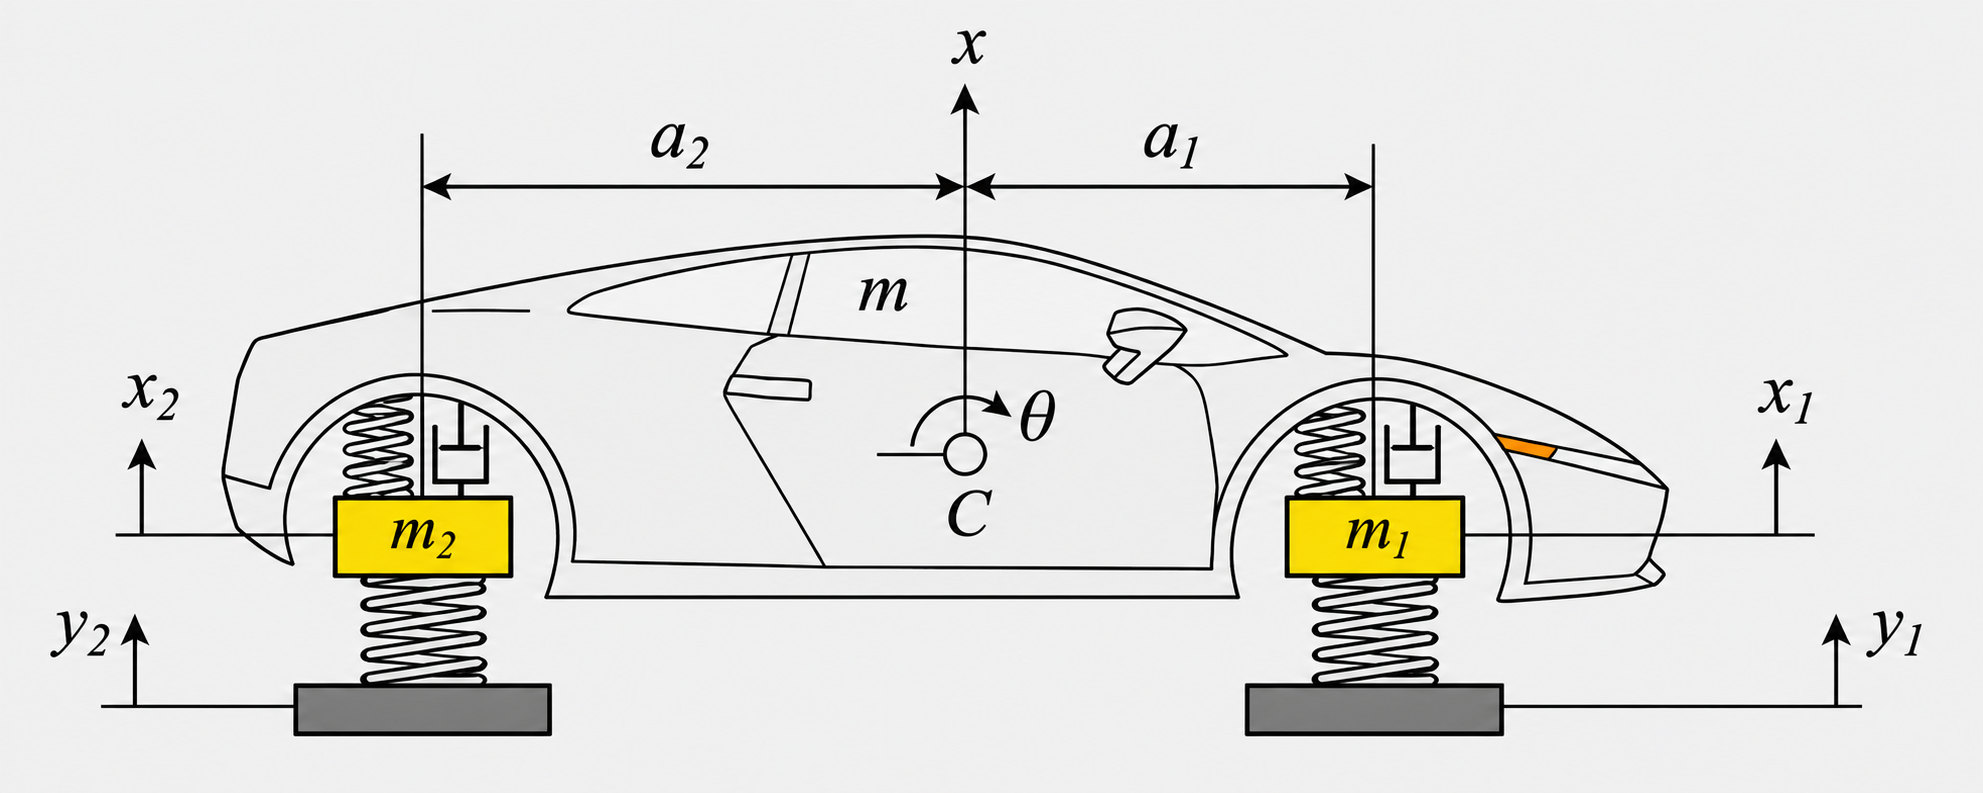



*Illustrative vehicle-suspension schematic.* The front wheel is on the **right**, indexed 1; the rear wheel is on the **left**, indexed 2.

> **Notation reconciliation.** The uploaded **drawing** labels the wheel-mass coordinates $x_1,x_2$ and the road coordinates $y_1,y_2$, whereas the uploaded **equations** use $y_1,y_2$ for wheel-mass coordinates and assume fixed roads. This notebook consistently follows the **equations**: wheel masses are $y_1,y_2$, and road inputs are newly named $r_1,r_2$. Thus the drawing's $x_i$ corresponds to the equation's $y_i$, and the drawing's $y_i$ corresponds to our $r_i$. The body heave coordinate $x$ is unchanged.

### 1.1 Coordinates, parameters, and conventions


Let the **generalized displacement** be

$$
X=\begin{bmatrix}y_1&y_2&x&\theta\end{bmatrix}^{T},
$$

where $y_1$ and $y_2$ are the front and rear **unsprung-mass** displacements, $x$ is vehicle-body heave at $C$, and $\theta$ is the small pitch angle. We take positive $x$, $y_1$, and $y_2$ **upward**, and positive $\theta$ as **clockwise** (front downward, rear upward).

The body attachment-point displacements are therefore

$$x_1^{\mathrm b}=x-a_1\theta,\qquad x_2^{\mathrm b}=x+a_2\theta.$$

Here $m$ is the sprung mass, $I$ its mass moment of inertia about $C$, $m_1,m_2$ the unsprung masses, $a_1,a_2$ the horizontal distances from $C$ to the front/rear suspensions, $k_s$ the stiffness of **each** suspension spring, $c_s$ its viscous damping coefficient, and $k_t$ the stiffness of **each** tire. The original notebook uses identical parameters for both suspension units and tires.

**Small-displacement model.** Displacements are measured from the *static equilibrium*; consequently gravity does not appear explicitly in these linearized equations. We assume a rigid body, small pitch, linear springs, viscous damping, and continuous tire contact.

| Quantity | Units | Meaning |
|:--|:--|:--|
| $m,m_1,m_2$ | kg | Sprung and unsprung masses |
| $I$ | kg m$^2$ | Pitch mass moment of inertia |
| $a_1,a_2$ | m | Distances from $C$ to the front and rear suspension |
| $k_s,k_t$ | N/m | Suspension and tire stiffness per end |
| $c_s$ | N s/m | Suspension damping per end |
| $x,y_1,y_2,r_1,r_2$ | m | Vertical displacements and road elevations |
| $\theta$ | rad | Small clockwise pitch angle |

### 1.2 Equations of motion

Let the suspension deflections be

$$
\delta_1=x-a_1\theta-y_1,\qquad
\delta_2=x+a_2\theta-y_2.
$$

Define the suspension and tire forces as

$$
\begin{aligned}
F_{s,i}&=k_s\delta_i+c_s\dot{\delta}_i,\\
F_{t,i}&=k_t(y_i-r_i)+c_t(\dot y_i-\dot r_i),
\qquad i=1,2.
\end{aligned}
$$

All displacements are measured relative to the static equilibrium configuration, so the constant gravitational terms have already been eliminated.

**Newton's second law**, applied to the two unsprung masses and the vehicle body, together with the moment equation about its centre of mass, gives

$$
\begin{aligned}
m_1\ddot y_1 &= F_{s,1}-F_{t,1},\\
m_2\ddot y_2 &= F_{s,2}-F_{t,2},\\
m\ddot x &= -F_{s,1}-F_{s,2}+f,\\
I\ddot\theta &= a_1F_{s,1}-a_2F_{s,2}+T.
\end{aligned}
$$

Here $f$ and $T$ denote externally applied vertical force and pitch moment, respectively.

**Compact matrix construction.** Define

$$
X=
\begin{bmatrix}
y_1\\y_2\\x\\\theta
\end{bmatrix},
\qquad
B_s=
\begin{bmatrix}
-1&0&1&-a_1\\
0&-1&1&a_2
\end{bmatrix},
\qquad
B_t=
\begin{bmatrix}
1&0&0&0\\
0&1&0&0
\end{bmatrix}.
$$

Then

$$
\delta=B_sX,\qquad
B_tX=\begin{bmatrix}y_1\\y_2\end{bmatrix}.
$$

Consequently, the force vectors can be expressed as

$$
\begin{aligned}
F_s&=k_sB_sX+c_sB_s\dot X,\\
F_t&=k_t(B_tX-r)+c_t(B_t\dot X-\dot r),
\end{aligned}
$$

where $r=[r_1,r_2]^T$.

The four Newton equations can therefore be assembled into

$$
M\ddot X+B_s^TF_s+B_t^TF_t
=
\begin{bmatrix}
0\\0\\f\\T
\end{bmatrix},
$$

with

$$
M=\operatorname{diag}(m_1,m_2,m,I).
$$

Substituting the force expressions gives

$$
\boxed{
M\ddot X+C\dot X+KX
=B_t^T(k_tr+c_t\dot r)
+S\begin{bmatrix}f\\T\end{bmatrix}
}
$$

where

$$
\boxed{
\begin{aligned}
K&=k_sB_s^TB_s+k_tB_t^TB_t,\\
C&=c_sB_s^TB_s+c_tB_t^TB_t,\\
S&=
\begin{bmatrix}
0&0\\
0&0\\
1&0\\
0&1
\end{bmatrix}.
\end{aligned}
}
$$

For $c_t=0$, this reproduces the original notebook's $M$, $C$, and $K$.

**First-order state model.** With $Y=[X^T,\dot X^T]^T$,

$$
\dot Y=AY+B_u
\begin{bmatrix}f\\T\end{bmatrix}
+B_rr+B_{\dot r}\dot r,
$$

where

$$
A=
\begin{bmatrix}
0&I_4\\
-M^{-1}K&-M^{-1}C
\end{bmatrix},
$$

and

$$
\begin{aligned}
B_u&=
\begin{bmatrix}
0_{4\times2}\\
M^{-1}S
\end{bmatrix},\\[4pt]
B_r&=
\begin{bmatrix}
0_{4\times2}\\
M^{-1}B_t^Tk_t
\end{bmatrix},\\[4pt]
B_{\dot r}&=
\begin{bmatrix}
0_{4\times2}\\
M^{-1}B_t^Tc_t
\end{bmatrix}.
\end{aligned}
$$

The factorized expressions $B_s^TB_s$ and $B_t^TB_t$ make the symmetry and positive-semidefiniteness of the stiffness and damping contributions immediately apparent, without introducing an energy formulation.


## 2. Python setup and baseline parameters

All parameter values below are **illustrative**, rather than measurements supplied in the source notebook. Each front/rear suspension and each tire uses the same $k_s,c_s,k_t$ as in the original formulation. The body geometry is slightly asymmetric by default, which makes coupling easier to explore.

In [ ]:
import sys
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy.integrate import solve_ivp, cumulative_simpson
from scipy.linalg import eigh
import sympy as sp
from IPython.display import display

pio.templates.default = "plotly_white"
try:
    import google.colab  # the Colab renderer works best within Colab
    pio.renderers.default = "colab"
except ImportError:
    pio.renderers.default = "notebook_connected"
np.set_printoptions(precision=4, suppress=True)

@dataclass(frozen=True)
class VehicleParameters:
    m: float = 1200.0        # sprung mass [kg]
    I: float = 2100.0        # pitch inertia [kg m^2]
    m1: float = 45.0         # front unsprung mass [kg]
    m2: float = 45.0         # rear unsprung mass [kg]
    a1: float = 1.25         # C to front [m]
    a2: float = 1.45         # C to rear [m]
    ks: float = 28000.0      # EACH suspension spring [N/m]
    kt: float = 190000.0     # EACH tire [N/m]
    cs: float = 2200.0       # EACH suspension damper [N s/m]
    ct: float = 0.0          # optional tire damping [N s/m]; 0 = source model

p = VehicleParameters()

display(pd.DataFrame(
    [(k, v) for k, v in vars(p).items()],
    columns=["Parameter", "Illustrative value"]
).set_index("Parameter"))

In [ ]:
def matrices(p):
    """Return M, C, K and the relative-deflection mappings B_s, B_t."""
    B_s = np.array([[-1., 0., 1., -p.a1],
                    [ 0.,-1., 1.,  p.a2]])
    B_t = np.array([[1.,0.,0.,0.],
                    [0.,1.,0.,0.]])
    M = np.diag([p.m1, p.m2, p.m, p.I])
    K = p.ks * (B_s.T @ B_s) + p.kt * (B_t.T @ B_t)
    C = p.cs * (B_s.T @ B_s) + p.ct * (B_t.T @ B_t)
    return M, C, K, B_s, B_t

M, C, K, B_s, B_t = matrices(p)
assert np.allclose(K, K.T) and np.allclose(C, C.T)
assert np.min(np.linalg.eigvalsh(M)) > 0
assert np.min(np.linalg.eigvalsh(K)) > 0
assert np.min(np.linalg.eigvalsh(C)) > -1e-9

fig = make_subplots(rows=1, cols=2, subplot_titles=("Stiffness K", "Damping C"))
for j, mat in enumerate([K, C], start=1):
    fig.add_trace(go.Heatmap(
        z=mat, x=["y₁","y₂","x","θ"], y=["y₁","y₂","x","θ"],
        colorscale="RdBu", zmid=0, showscale=False,
        text=np.round(mat, 1), texttemplate="%{text}", hovertemplate="%{y},%{x}: %{z:.3g}<extra></extra>"
    ), row=1, col=j)
fig.update_layout(title="Coupled system matrices (entries have coordinate-dependent units)",
                  height=420, width=1050, margin=dict(t=90))
fig.show()
print("Checks passed: M positive definite; K positive definite; C positive semidefinite.")

### 2.1 Symbolic verification against the source matrices

A direct symbolic comparison helps catch a sign error in the pitch-coupling entries $\pm a_i k_s$. The extra tire damper is set to zero here, because it was **not** in the original notebook.

In [ ]:
m1_s, m2_s, m_s, I_s, a1_s, a2_s, ks_s, kt_s, cs_s = sp.symbols(
    'm_1 m_2 m I a_1 a_2 k_s k_t c_s', positive=True)
Bs_s = sp.Matrix([[-1, 0, 1, -a1_s], [0, -1, 1, a2_s]])
Bt_s = sp.Matrix([[1,0,0,0], [0,1,0,0]])
K_factored = ks_s*Bs_s.T*Bs_s + kt_s*Bt_s.T*Bt_s
C_factored = cs_s*Bs_s.T*Bs_s
K_source = sp.Matrix([
    [kt_s+ks_s, 0, -ks_s, a1_s*ks_s],
    [0, kt_s+ks_s, -ks_s, -a2_s*ks_s],
    [-ks_s, -ks_s, 2*ks_s, (a2_s-a1_s)*ks_s],
    [a1_s*ks_s, -a2_s*ks_s, (a2_s-a1_s)*ks_s, (a1_s**2+a2_s**2)*ks_s]
])
C_source = sp.Matrix([
    [cs_s, 0, -cs_s, a1_s*cs_s],
    [0, cs_s, -cs_s, -a2_s*cs_s],
    [-cs_s, -cs_s, 2*cs_s, (a2_s-a1_s)*cs_s],
    [a1_s*cs_s, -a2_s*cs_s, (a2_s-a1_s)*cs_s, (a1_s**2+a2_s**2)*cs_s]
])
assert sp.simplify(K_factored - K_source) == sp.zeros(4)
assert sp.simplify(C_factored - C_source) == sp.zeros(4)
print("Symbolic check passed: the factorized K and C equal the uploaded notebook's matrices.")

## 3. Natural frequencies and mode shapes

For the **undamped** system, solve the generalized symmetric eigenproblem

$$K\phi_j=\omega_j^2M\phi_j,\qquad \phi_i^TM\phi_j=\delta_{ij}.$$

The natural frequencies in hertz are $f_j=\omega_j/(2\pi)$. With these mass-normalized modes, $\Phi^TM\Phi=I$ and $\Phi^TK\Phi=\operatorname{diag}(\omega_j^2)$.

**Interpretation of the heatmap:** the four plotted quantities are *physical vertical displacements* at the front/rear wheel masses and the front/rear body attachment points. They are normalized within each mode. That avoids graphing radians and meters on a common, misleading scale.

In [ ]:
def modal_analysis(p):
    M, C, K, Bs, Bt = matrices(p)
    lam, phi = eigh(K, M)        # mass-normalized mode vectors
    omega = np.sqrt(lam)
    return omega, phi

def physical_shape(phi, p):
    """Convert a 4-vector into front/rear wheel and body-point vertical displacements."""
    return np.array([phi[0], phi[1], phi[2]-p.a1*phi[3], phi[2]+p.a2*phi[3]])

omega, Phi = modal_analysis(p)
frequencies = omega / (2*np.pi)
assert np.allclose(Phi.T @ M @ Phi, np.eye(4), atol=1e-10)
assert np.allclose(Phi.T @ K @ Phi, np.diag(omega**2), atol=1e-8)

freq_table = pd.DataFrame({
    "Mode": np.arange(1,5),
    "f [Hz]": frequencies,
    "ω [rad/s]": omega,
    "Period [s]": 1/frequencies,
})
display(freq_table.style.format({"f [Hz]":"{:.3f}", "ω [rad/s]":"{:.3f}", "Period [s]":"{:.3f}"}))

shape_matrix = np.column_stack([physical_shape(Phi[:,j],p) for j in range(4)])
shape_matrix /= np.max(np.abs(shape_matrix), axis=0)

fig = go.Figure(go.Heatmap(
    z=shape_matrix,
    x=[f"Mode {j+1} · {frequencies[j]:.2f} Hz" for j in range(4)],
    y=["Front wheel y₁", "Rear wheel y₂", "Front body x−a₁θ", "Rear body x+a₂θ"],
    zmin=-1, zmax=1, colorscale="RdBu", reversescale=True,
    text=np.round(shape_matrix,2), texttemplate="%{text}",
    colorbar=dict(title="Relative vertical motion")
))
fig.update_layout(title="Normal modes: in-phase and out-of-phase movements", height=470, width=1050)
fig.show()

### 3.1 Demonstration: why geometric symmetry matters

If $m_1=m_2$ **and** $a_1=a_2$, the front/rear interchange symmetry separates the motion into two independent groups: symmetric wheel motion associated with **heave**, and antisymmetric wheel motion associated with **pitch**. The model still has four modes (two per group). Unequal axle distances or unsprung masses generally mix those motions.

Compare the mode shapes of the asymmetric baseline vehicle and an otherwise identical symmetric vehicle.

In [ ]:
p_symmetric = replace(p, a1=(p.a1+p.a2)/2, a2=(p.a1+p.a2)/2, m2=p.m1)
om_s, Phi_s = modal_analysis(p_symmetric)
shape_s = np.column_stack([physical_shape(Phi_s[:,j], p_symmetric) for j in range(4)])
shape_s /= np.max(np.abs(shape_s), axis=0)

fig = make_subplots(rows=1, cols=2, subplot_titles=("Baseline: a₁ ≠ a₂", "Symmetric: a₁ = a₂"))
for col, array, om in [(1, shape_matrix, omega), (2, shape_s, om_s)]:
    fig.add_trace(go.Heatmap(
        z=array, zmin=-1, zmax=1, colorscale="RdBu", reversescale=True,
        x=[f"{f:.2f} Hz" for f in om/(2*np.pi)],
        y=["Front wheel", "Rear wheel", "Front body", "Rear body"],
        showscale=(col == 2), text=np.round(array, 2), texttemplate="%{text}"
    ), row=1, col=col)
fig.update_layout(height=475, width=1170, title="Symmetry reveals cleaner bounce/pitch mode families")
fig.show()

### 3.2 Modal damping is not generally diagonal

In undamped modal coordinates $X=\Phi z$, the damped dynamics become

$$\ddot z+\underbrace{\Phi^TC\Phi}_{C_{\mathrm{modal}}}\dot z+\operatorname{diag}(\omega_j^2)z=\Phi^TF.$$

Even though $M$ and $K$ are diagonalized, $C_{\mathrm{modal}}$ **need not be diagonal**. The original model has suspension damping but no tire damping; it is not automatically proportional damping. This matters if independent damped modal oscillators are assumed.

In [ ]:
C_modal = Phi.T @ C @ Phi
zeta_like = np.diag(C_modal)/(2*omega)   # diagnostic only, not exact modal damping ratios
coupling = C_modal / np.sqrt(np.outer(np.diag(C_modal), np.diag(C_modal)))
np.fill_diagonal(coupling, 1)
print("Diagonal-only damping-ratio estimates (not exact if modes are coupled):", np.round(zeta_like, 3))
print("Largest absolute normalized off-diagonal modal damping:",
      f"{np.max(np.abs(coupling - np.eye(4))):.3f}")
fig = go.Figure(go.Heatmap(
    z=coupling, x=[f"Mode {j}" for j in range(1,5)],
    y=[f"Mode {j}" for j in range(1,5)], zmin=-1, zmax=1, zmid=0,
    colorscale="RdBu", text=np.round(coupling,2), texttemplate="%{text}"
))
fig.update_layout(title="Normalized modal damping coupling", width=650, height=490)
fig.show()

## 4. Simulate a road bump with SciPy

### 4.1 A smooth bump and the front-to-rear time delay

For a car moving forward at constant speed $v$, take a raised-cosine bump of height $h$ and longitudinal length $\ell$:

$$
r_1(t)=\begin{cases}
\dfrac{h}{2}\left[1-\cos\!\left(2\pi\dfrac{t-t_0}{\ell/v}\right)\right],& t_0\le t\le t_0+\ell/v,\\
0,&\text{otherwise.}
\end{cases}
$$

The rear axle reaches the same bump **later** by $\tau=(a_1+a_2)/v$. Thus $r_2(t)=r_1(t-\tau)$. The smooth bump avoids unphysical discontinuities in road *height* and road *velocity*.

**Important distinction:** $f(t)$ and $T(t)$ in the original notebook are direct forces/moments on the sprung body. Road displacement is a **base excitation** entering the tire forces, not a direct body force. Below we use $f=T=0$ unless noted.

In [ ]:
@dataclass(frozen=True)
class RoadBump:
    height: float = 0.045   # peak road displacement [m]
    length: float = 1.0     # bump length along road [m]
    speed: float = 12.0     # vehicle speed [m/s]
    t_front: float = 0.65  # time front tire meets bump [s]

    def road(self, t, p):
        """Road elevations and their time derivatives: ([r1,r2], [r1dot,r2dot])."""
        duration = self.length / self.speed
        delay = (p.a1 + p.a2) / self.speed
        t = np.asarray(t, dtype=float)
        def one(start):
            phase = (t - start) / duration
            active = (phase >= 0) & (phase <= 1)
            h = np.where(active, self.height/2 * (1-np.cos(2*np.pi*phase)), 0.)
            dh = np.where(active, self.height*np.pi/duration * np.sin(2*np.pi*phase), 0.)
            return h, dh
        r1, dr1 = one(self.t_front)
        r2, dr2 = one(self.t_front+delay)
        return np.stack([r1,r2], axis=-1), np.stack([dr1,dr2], axis=-1)

bump = RoadBump()
t = np.linspace(0, 7, 2001)
r, dr = bump.road(t, p)
fig = go.Figure()
fig.add_scatter(x=t, y=1e3*r[:,0], name="Front road r₁", mode="lines")
fig.add_scatter(x=t, y=1e3*r[:,1], name="Rear road r₂", mode="lines")
fig.update_layout(title=f"45 mm bump · {bump.speed:g} m/s · rear delay {(p.a1+p.a2)/bump.speed:.3f} s",
                  xaxis_title="Time [s]", yaxis_title="Road elevation [mm]", height=390)
fig.show()

In [ ]:
def simulate(p, t, initial=None, bump=None, external=None, max_step=0.006):
    """Solve the fully coupled 8-state linear system using scipy.solve_ivp.

    external(t) optionally returns [f(t), T(t)] in N and N m.
    """
    M, C, K, Bs, Bt = matrices(p)
    massdiag = np.diag(M)
    initial = np.zeros(8) if initial is None else np.asarray(initial, dtype=float)
    def rhs(tt, state):
        q, dq = state[:4], state[4:]
        if bump is None:
            r = np.zeros(2)
            dr = np.zeros(2)
        else:
            r, dr = bump.road(tt, p)
        u = np.zeros(2) if external is None else np.asarray(external(tt), dtype=float)
        direct = np.array([0.,0.,u[0],u[1]])
        forcing = Bt.T @ (p.kt*r + p.ct*dr) + direct
        ddq = (forcing - C@dq - K@q) / massdiag
        return np.r_[dq, ddq]
    sol = solve_ivp(rhs, (float(t[0]), float(t[-1])), initial,
                    t_eval=t, method="DOP853", max_step=max_step,
                    rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def outputs(sol, p, bump=None, external=None):
    M, C, K, Bs, Bt = matrices(p)
    t = sol.t
    q, dq = sol.y[:4].T, sol.y[4:].T
    if bump is None:
        r, dr = np.zeros((len(t),2)), np.zeros((len(t),2))
    else:
        r, dr = bump.road(t, p)
    direct = np.array([external(tt) if external is not None else [0.,0.] for tt in t])
    F = np.column_stack([np.zeros(len(t)), np.zeros(len(t)), direct])
    F[:,0:2] = p.kt*r + p.ct*dr
    ddq = (F-q@K.T-dq@C.T) / np.diag(M)[None,:]
    return {
        "t": t, "q": q, "dq": dq, "ddq": ddq, "r": r, "dr": dr,
        "front_body": q[:,2]-p.a1*q[:,3],
        "rear_body": q[:,2]+p.a2*q[:,3],
        "suspension_deflection": q @ Bs.T,
        "tire_dynamic_upward_force": p.kt*(r-q[:,:2])+p.ct*(dr-dq[:,:2]),
    }

sol = simulate(p, t, bump=bump)
o = outputs(sol, p, bump=bump)
print(f"Numerical solution: {len(sol.t):,} sample times; integration successful.")

### 4.2 Interpreting the time histories

* The wheel masses $y_i$ respond quickly because their inertia is small and the tire stiffness is high (wheel-hop).
* The body heave $x$ and pitch $\theta$ show slower, lower-frequency motion.
* The body does not necessarily follow road elevation; **damping and inertia filter the input**.
* The suspension travel $\delta_i=x_i^{\mathrm b}-y_i$ measures relative movement across the suspension elements.

The figures use consistent units: **mm**, **degrees**, and **m/s$^2$**.

In [ ]:
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.09,
                    subplot_titles=("Wheel and road displacement", "Rigid-body heave and body-end motion",
                                    "Pitch angle"))
for col, name in [(0,"Front"),(1,"Rear")]:
    fig.add_scatter(x=t, y=1000*o["r"][:,col], name=f"{name} road", line=dict(dash="dot"), row=1,col=1)
    fig.add_scatter(x=t, y=1000*o["q"][:,col], name=f"{name} wheel", row=1,col=1)
for data, name in [(o["q"][:,2],"Body center x"),(o["front_body"],"Front body"),
                   (o["rear_body"],"Rear body")]:
    fig.add_scatter(x=t, y=1000*data, name=name, row=2,col=1)
fig.add_scatter(x=t, y=np.rad2deg(o["q"][:,3]), name="Pitch θ", row=3,col=1)
fig.update_yaxes(title_text="Displacement [mm]", row=1,col=1)
fig.update_yaxes(title_text="Displacement [mm]", row=2,col=1)
fig.update_yaxes(title_text="Pitch [deg]", row=3,col=1)
fig.update_xaxes(title_text="Time [s]", row=3,col=1)
fig.update_layout(title="Four-DOF response to a single bump", height=940,
                  legend=dict(orientation="h", y=-0.10), hovermode="x unified")
fig.show()

### 4.3 Comfort, suspension travel, and road holding

Several performance indicators reveal different aspects of the same response:

* **Comfort proxy:** RMS sprung-body vertical acceleration $\mathrm{RMS}(\ddot x)$ over the selected observation window. For a full ride-comfort evaluation, standardized frequency-weighting would also be needed.
* **Suspension travel:** peak $|\delta_1|$ and $|\delta_2|$. Large values suggest a risk of hitting a bump/rebound stop.
* **Road holding proxy:** maximum dynamic tire-force deviation, here $\Delta F_{ti}=k_t(r_i-y_i)+c_t(\dot r_i-\dot y_i)$.
* **Tire contact:** the linear model does not enforce contact loss. A preliminary indicator is $F_{ti,0}+\Delta F_{ti}$, where the static tire loads are approximately

$$
F_{t1,0}\approx mg\frac{a_2}{a_1+a_2}+m_1g,
\qquad
F_{t2,0}\approx mg\frac{a_1}{a_1+a_2}+m_2g.
$$

A negative value is a **warning that the always-in-contact linear model has left its valid regime**, not an actual prediction of a negative contact force.

In [ ]:
def response_metrics(o, p, window=(0.5,4.0)):
    t=o["t"]
    mask=(t>=window[0]) & (t<=window[1])
    ddx=o["ddq"][mask,2]
    delta=o["suspension_deflection"][mask]
    dFt=o["tire_dynamic_upward_force"][mask]
    g=9.81
    static_load=np.array([
        p.m*g*p.a2/(p.a1+p.a2)+p.m1*g,
        p.m*g*p.a1/(p.a1+p.a2)+p.m2*g
    ])
    return {
        "RMS body accel [m/s²]":np.sqrt(np.mean(ddx**2)),
        "Peak heave [mm]":1000*np.max(np.abs(o["q"][mask,2])),
        "Peak pitch [deg]":np.rad2deg(np.max(np.abs(o["q"][mask,3]))),
        "Peak front susp travel [mm]":1000*np.max(np.abs(delta[:,0])),
        "Peak rear susp travel [mm]":1000*np.max(np.abs(delta[:,1])),
        "Peak |Δtire force| [kN]":np.max(np.abs(dFt))/1000,
        "Minimum contact-force proxy [kN]":np.min(static_load[None,:]+dFt)/1000
    }

metrics=response_metrics(o,p)
display(pd.DataFrame.from_dict(metrics, orient="index", columns=["Value"]).style.format("{:.3f}"))

fig=make_subplots(rows=2,cols=1, shared_xaxes=True, vertical_spacing=0.13,
                  subplot_titles=("Relative suspension travel", "Dynamic tire-force deviation"))
for k,n in enumerate(["Front", "Rear"]):
    fig.add_scatter(x=t,y=1000*o["suspension_deflection"][:,k],name=f"{n} travel", row=1,col=1)
    fig.add_scatter(x=t,y=o["tire_dynamic_upward_force"][:,k]/1000,
                    name=f"{n} Δtire force",row=2,col=1)
fig.update_yaxes(title_text="Suspension travel [mm]",row=1,col=1)
fig.update_yaxes(title_text="Force change [kN]",row=2,col=1)
fig.update_xaxes(title_text="Time [s]",row=2,col=1)
fig.update_layout(height=680, title="Suspension and tire responses", hovermode="x unified",
                  legend=dict(orientation="h",y=-0.15))
fig.show()

## 5. Free vibration and energy consistency

For zero road displacement and zero applied force/moment, the total mechanical energy is

$$
E(t)=\frac12\dot X^TM\dot X+\frac12X^TKX.
$$

Since $M\ddot X+C\dot X+KX=0$ and $M,K,C$ are symmetric,

$$\boxed{\dot E=-\dot X^TC\dot X\le0.}$$

Thus the energy must **decrease** in the damped system (except where instantaneous damping power is zero). If $c_s=c_t=0$, the energy must remain **constant**. These provide strong numerical checks on both the model and the integrator.

In [ ]:
def energy_components(sol,p):
    M,C,K,_,_=matrices(p)
    q,dq=sol.y[:4].T,sol.y[4:].T
    kinetic=0.5*np.einsum("ni,ij,nj->n",dq,M,dq)
    potential=0.5*np.einsum("ni,ij,nj->n",q,K,q)
    loss_rate=np.einsum("ni,ij,nj->n",dq,C,dq)
    return kinetic,potential,loss_rate

free_t=np.linspace(0,9,2201)
free_initial=np.array([0.,0.,0.035,np.deg2rad(0.65),0.,0.,0.,0.])
free_sol=simulate(p,free_t,initial=free_initial)
T_free,V_free,p_loss=energy_components(free_sol,p)
E_free=T_free+V_free
D_free=cumulative_simpson(p_loss,x=free_t,initial=0.)

p_undamped=replace(p,cs=0.,ct=0.)
undamped_sol=simulate(p_undamped,free_t,initial=free_initial)
Tu,Vu,_=energy_components(undamped_sol,p_undamped)
Eu=Tu+Vu

balance_error=np.max(np.abs(E_free[0]-E_free-D_free))/E_free[0]
conservation_error=np.max(np.abs(Eu-Eu[0]))/Eu[0]
print(f"Damped energy-balance max relative error: {balance_error:.2e}")
print(f"Undamped energy-conservation max relative error: {conservation_error:.2e}")
assert balance_error<5e-4, "Energy balance needs a finer time grid or integrator tolerance"
assert conservation_error<1e-4, "Undamped energy should be conserved"

fig=make_subplots(rows=1,cols=2,subplot_titles=("Damped: energy vs cumulative dissipation",
                                                   "Undamped: normalized energy stays constant"))
fig.add_scatter(x=free_t,y=E_free/E_free[0],name="Total energy / E(0)",row=1,col=1)
fig.add_scatter(x=free_t,y=D_free/E_free[0],name="Dissipated energy / E(0)",row=1,col=1)
fig.add_scatter(x=free_t,y=(E_free+D_free)/E_free[0],
                name="Energy + loss (should be 1)",line=dict(dash="dot"),row=1,col=1)
fig.add_scatter(x=free_t,y=Eu/Eu[0],name="Undamped energy / E(0)",row=1,col=2)
fig.update_xaxes(title_text="Time [s]")
fig.update_yaxes(title_text="Normalized energy")
fig.update_layout(title="Energy verification of the simulator",height=500,width=1160)
fig.show()

## 6. Frequency response: resonance, wheel-hop, and axle phase

For harmonic road input $r(t)=\Re\{\widehat r\,e^{i\omega t}\}$, the steady-state complex amplitude satisfies

$$\widehat X(\omega)=\underbrace{\left(K-\omega^2M+i\omega C\right)^{-1}}_{\text{dynamic compliance}}
B_t^T\left(k_t+i\omega c_t\right)\widehat r.$$

Three excitation cases are worth contrasting:

1. **Front-only road input:** $\widehat r=[1,0]^T$.
2. **Both axles in phase:** $\widehat r=[1,1]^T$.
3. **The same traveling sinusoidal road profile at speed $v$:** $\widehat r=[1,e^{-i\omega\tau}]^T$, $\tau=(a_1+a_2)/v$.

The amplitude of the body heave transfer function is $|\widehat x/\widehat r_1|$ (m/m). Pitch response is shown as **degrees per 10 mm of sinusoidal road amplitude**. Because the front and rear input phases differ with speed, pitch response can change substantially even when the bump profile is unchanged.

In [ ]:
def frequency_response(p, f_hz, road_type="front", speed=12.):
    M,C,K,Bs,Bt=matrices(p)
    response=np.zeros((len(f_hz),4),dtype=complex)
    delay=(p.a1+p.a2)/speed
    for i, f in enumerate(f_hz):
        w=2*np.pi*f
        if road_type=="front":
            rhat=np.array([1.,0.])
        elif road_type=="in-phase":
            rhat=np.array([1.,1.])
        elif road_type=="traveling":
            rhat=np.array([1.,np.exp(-1j*w*delay)])
        else:
            raise ValueError("Unknown road_type")
        D=K-w**2*M+1j*w*C
        fhat=Bt.T@((p.kt+1j*w*p.ct)*rhat)
        response[i]=np.linalg.solve(D,fhat)
    return response

fgrid=np.geomspace(0.15,22.,700)
response_cases={
    "Front tire only":frequency_response(p,fgrid,"front"),
    "Two axles, in phase":frequency_response(p,fgrid,"in-phase"),
    f"Traveling road, {bump.speed:g} m/s":frequency_response(p,fgrid,"traveling",bump.speed)
}
fig=make_subplots(rows=2,cols=1,shared_xaxes=True,vertical_spacing=0.11,
                  subplot_titles=("Body heave displacement gain", "Body pitch gain"))
for label,H in response_cases.items():
    fig.add_scatter(x=fgrid,y=np.abs(H[:,2]),name=label,row=1,col=1)
    fig.add_scatter(x=fgrid,y=np.abs(H[:,3])*180/np.pi*0.01,
                    name=label,showlegend=False,row=2,col=1)
for f in frequencies:
    fig.add_vline(x=f,line_width=1,line_dash="dot",line_color="gray",row=1,col=1)
    fig.add_vline(x=f,line_width=1,line_dash="dot",line_color="gray",row=2,col=1)
fig.update_xaxes(type="log",title_text="Excitation frequency [Hz]",row=2,col=1)
fig.update_yaxes(type="log",title_text="|x̂/r̂| [m/m]",row=1,col=1)
fig.update_yaxes(type="log",title_text="|θ̂| [deg per 10 mm]",row=2,col=1)
fig.update_layout(title="Road-to-body transfer functions · dotted lines = undamped natural frequencies",
                  height=810,hovermode="x unified",legend=dict(orientation="h",y=-0.13))
fig.show()

### 6.1 Demonstration: damping changes resonance, but not in a uniformly beneficial way

When the suspension damping coefficient increases, resonant peaks may reduce, but high-frequency vibration transmissibility can increase. The plots below compare the road-to-body heave frequency response for different suspension damping values. No modal decoupling assumption is used: the complete $4\times4$ complex system is solved at each frequency.

In [ ]:
fig=go.Figure()
for cs in [0.,800.,2200.,5000.]:
    pj=replace(p,cs=cs)
    H=frequency_response(pj,fgrid,"in-phase")
    fig.add_scatter(x=fgrid,y=np.abs(H[:,2]),name=f"cₛ = {cs:,.0f} N s/m")
fig.update_xaxes(type="log",title_text="Frequency [Hz]")
fig.update_yaxes(type="log",title_text="Heave gain [m/m]")
fig.update_layout(title="Damping: suppression of peaks versus frequency transmission",
                  height=490,hovermode="x unified")
fig.show()

## 7. Design investigation: ride comfort versus suspension travel

A larger damper coefficient does not automatically make a suspension superior. For the **same bump and speed**, compare

* the **RMS** body acceleration over a fixed time window, and
* the **maximum suspension travel** (worst of front and rear).

These proxies highlight the trade-off, without pretending they are a complete industrial ride-quality criterion. This sweep is a *parameter study* of the **illustrative** vehicle, not a universal recommendation for damper sizing.

In [ ]:
cs_values=np.array([350.,650.,950.,1400.,1800.,2200.,3000.,4200.,6000.])
compact_t=np.linspace(0,4.3,1251)
rows=[]
for cs in cs_values:
    pp=replace(p,cs=float(cs))
    ss=simulate(pp,compact_t,bump=bump,max_step=0.008)
    oo=outputs(ss,pp,bump=bump)
    met=response_metrics(oo,pp,window=(0.5,4.0))
    rows.append({"c_s":cs,"RMS acceleration":met["RMS body accel [m/s²]"],
                 "Max suspension travel":max(met["Peak front susp travel [mm]"],
                                              met["Peak rear susp travel [mm]"]),
                 "Max tire force":met["Peak |Δtire force| [kN]"]})
sweep=pd.DataFrame(rows)
display(sweep.style.format({"c_s":"{:.0f}","RMS acceleration":"{:.3f}",
                            "Max suspension travel":"{:.2f}","Max tire force":"{:.2f}"}))

fig=make_subplots(specs=[[{"secondary_y":True}]])
fig.add_scatter(x=sweep["c_s"],y=sweep["RMS acceleration"],
                name="RMS body acceleration",mode="lines+markers",secondary_y=False)
fig.add_scatter(x=sweep["c_s"],y=sweep["Max suspension travel"],
                name="Max |suspension travel|",mode="lines+markers",secondary_y=True)
fig.update_xaxes(title_text="Suspension damping per unit cₛ [N s/m]")
fig.update_yaxes(title_text="RMS heave acceleration [m/s²]",secondary_y=False)
fig.update_yaxes(title_text="Maximum suspension travel [mm]",secondary_y=True)
fig.update_layout(title="One parameter, competing design objectives",height=520,
                  legend=dict(orientation="h",y=-0.2))
fig.show()

### 7.1 Why vehicle speed matters

Changing $v$ changes **both** the duration of bump contact, $\ell/v$, and the front-to-rear delay, $(a_1+a_2)/v$. It is therefore not equivalent merely to shifting the same forcing curve in time.

This simulation compares the response to a **fixed spatial bump** at different speeds, while all vehicle properties remain unchanged.

In [ ]:
speed_values=[5.,8.,12.,16.,22.,30.]
speed_rows=[]
for speed in speed_values:
    bb=replace(bump,speed=speed)
    ss=simulate(p,compact_t,bump=bb,max_step=0.004)
    oo=outputs(ss,p,bump=bb)
    met=response_metrics(oo,p,window=(0.5,4.0))
    speed_rows.append({"Speed [m/s]":speed,
                       "Rear delay [s]":(p.a1+p.a2)/speed,
                       "RMS heave accel [m/s²]":met["RMS body accel [m/s²]"],
                       "Peak pitch [deg]":met["Peak pitch [deg]"]})
speed_df=pd.DataFrame(speed_rows)
display(speed_df.style.format("{:.3f}"))
fig=make_subplots(rows=1,cols=2,subplot_titles=("Acceleration versus speed", "Pitch versus speed"))
fig.add_scatter(x=speed_df["Speed [m/s]"],y=speed_df["RMS heave accel [m/s²]"],
                mode="lines+markers",name="RMS body accel",row=1,col=1)
fig.add_scatter(x=speed_df["Speed [m/s]"],y=speed_df["Peak pitch [deg]"],
                mode="lines+markers",name="Peak pitch",row=1,col=2)
fig.update_xaxes(title_text="Speed [m/s]")
fig.update_yaxes(title_text="RMS acceleration [m/s²]",row=1,col=1)
fig.update_yaxes(title_text="Peak pitch [deg]",row=1,col=2)
fig.update_layout(title="Speed alters the excitation time scale and phase relationship",height=470)
fig.show()

## 8. Plotly animation: rigid-body heave and pitch

The animated figure shows the *front and rear body points* joined by a rigid beam, their unsprung masses below, and the road beneath. **All vertical motion is magnified 8×** to make small displacements visible; the baseline heights of the layers are schematic offsets, not actual chassis clearances. The front and rear road elevations are plotted separately.

Use **Play**, **Pause**, or the time slider. This is a kinematic visualization of the *numerically simulated response*, not an additional dynamical approximation.

In [ ]:
mag=8.0
x_rear,x_front=-p.a2,p.a1
sample_indices=np.linspace(0,len(t)-1,100).round().astype(int)

def animation_traces(j):
    qr=o["q"][j]
    rf,rr=o["r"][j]
    body_rear=1.15+mag*(qr[2]+p.a2*qr[3])
    body_front=1.15+mag*(qr[2]-p.a1*qr[3])
    wheel_rear=0.55+mag*qr[1]
    wheel_front=0.55+mag*qr[0]
    road_rear=0.05+mag*rr
    road_front=0.05+mag*rf
    return [
        go.Scatter(x=[x_rear,x_front],y=[body_rear,body_front],
                   mode="lines+markers",line=dict(width=10),marker=dict(size=12),name="Rigid vehicle body"),
        go.Scatter(x=[x_rear,x_rear],y=[body_rear,wheel_rear],mode="lines+markers",
                   line=dict(width=3,dash="dot"),marker=dict(size=[4,15]),name="Rear suspension"),
        go.Scatter(x=[x_front,x_front],y=[body_front,wheel_front],mode="lines+markers",
                   line=dict(width=3,dash="dot"),marker=dict(size=[4,15]),name="Front suspension"),
        go.Scatter(x=[x_rear,x_rear],y=[wheel_rear,road_rear],mode="lines",
                   line=dict(width=4),name="Rear tire"),
        go.Scatter(x=[x_front,x_front],y=[wheel_front,road_front],mode="lines",
                   line=dict(width=4),name="Front tire"),
        go.Scatter(x=[x_rear-0.30,x_rear+0.30,None,x_front-0.30,x_front+0.30],
                   y=[road_rear,road_rear,None,road_front,road_front],
                   mode="lines",line=dict(width=7),name="Road surface")
    ]

frames=[go.Frame(name=f"{t[j]:.3f}",data=animation_traces(j)) for j in sample_indices]
fig=go.Figure(data=animation_traces(sample_indices[0]),frames=frames)
steps=[dict(label=f"{t[j]:.2f}",method="animate",
            args=[[f"{t[j]:.3f}"],dict(mode="immediate",frame=dict(duration=0,redraw=True),
                                       transition=dict(duration=0))]) for j in sample_indices]
fig.update_layout(
    title="Animated response to the road bump · vertical motion magnified ×8",
    xaxis=dict(title="Longitudinal position relative to C [m]",range=[-2.0,1.8]),
    yaxis=dict(title="Schematic vertical position [arbitrary offsets + magnified m]",range=[-0.35,2.05]),
    height=650, showlegend=True,
    updatemenus=[dict(type="buttons",showactive=False,x=0,y=-0.07,
                      buttons=[dict(label="▶ Play",method="animate",
                                    args=[None,dict(frame=dict(duration=65,redraw=True),
                                                    transition=dict(duration=0),fromcurrent=True)]),
                               dict(label="⏸ Pause",method="animate",
                                    args=[[None],dict(frame=dict(duration=0,redraw=True),
                                                      mode="immediate")])])],
    sliders=[dict(active=0,x=0.18,y=-0.05,len=0.78,steps=steps,
                  currentvalue=dict(prefix="t = ",suffix=" s"))],
    margin=dict(b=120)
)
fig.show()

## 9. Optional interactive experiment

Use the sliders to change vehicle speed and suspension damping *without editing the functions*. The two plots are regenerated with Plotly from the same numerical model. The experiment is intentionally optional; all previous cells work without `ipywidgets`.

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    try:
        from google.colab import output as colab_output
        colab_output.enable_custom_widget_manager()
    except ImportError:
        pass

    speed_slider=widgets.FloatSlider(value=bump.speed,min=4,max=28,step=2,
                                    description="Speed [m/s]",continuous_update=False,
                                    style={"description_width":"initial"})
    damper_slider=widgets.IntSlider(value=int(p.cs),min=400,max=6000,step=400,
                                    description="cₛ [N s/m]",continuous_update=False,
                                    style={"description_width":"initial"})
    interactive_area=widgets.Output()

    def redraw(change=None):
        with interactive_area:
            clear_output(wait=True)
            p_new=replace(p,cs=float(damper_slider.value))
            b_new=replace(bump,speed=float(speed_slider.value))
            t_new=np.linspace(0,4.3,1101)
            s_new=simulate(p_new,t_new,bump=b_new,max_step=0.008)
            o_new=outputs(s_new,p_new,bump=b_new)
            met=response_metrics(o_new,p_new,window=(0.5,4.0))
            fig=make_subplots(rows=2,cols=1,shared_xaxes=True,vertical_spacing=0.10,
                              subplot_titles=("Body displacement", "Body vertical acceleration"))
            fig.add_scatter(x=t_new,y=1000*o_new["q"][:,2],name="Heave x [mm]",row=1,col=1)
            fig.add_scatter(x=t_new,y=o_new["ddq"][:,2],name="Heave acceleration [m/s²]",row=2,col=1)
            fig.update_yaxes(title_text="Displacement [mm]",row=1,col=1)
            fig.update_yaxes(title_text="Acceleration [m/s²]",row=2,col=1)
            fig.update_xaxes(title_text="Time [s]",row=2,col=1)
            fig.update_layout(height=590,title=f"RMS body acceleration: {met['RMS body accel [m/s²]']:.3f} m/s²")
            fig.show()

    speed_slider.observe(redraw,names="value")
    damper_slider.observe(redraw,names="value")
    display(widgets.VBox([widgets.HBox([speed_slider,damper_slider]),interactive_area]))
    redraw()
except ImportError:
    print("Optional widgets unavailable. Install with: %pip install ipywidgets")

## 10. Additional demonstrations and exercises

### A. Tire stiffness and wheel-hop

Increase $k_t$ by a factor of 1.5 and recompute the modes. Which eigenfrequencies are most sensitive? Explain why tire stiffness mainly affects modes with substantial unsprung-mass motion.

### B. Symmetry breaking

Start from $a_1=a_2$ and $m_1=m_2$, then change **only** $a_1$. Inspect the modal heatmap and the response to equal in-phase road excitation. Which pure heave/pitch interpretations cease to be exact?

### C. Damping is not just “more is better”

Find a damping range that reduces a resonance peak but increases the response at a higher excitation frequency. Compare a frequency-domain prediction with a time-domain simulation.

### D. Front/rear excitation phase

For a sinusoidal road of wavelength $\lambda$, $\omega=2\pi v/\lambda$ and the rear phase lag is

$$\omega\tau=\frac{2\pi(a_1+a_2)}{\lambda}.$$

Notice that the phase delay depends on the *axle separation and road wavelength*, not directly on speed, even though the *excitation frequency* does depend on speed. At what wavelengths do the front and rear road inputs become nearly **in phase** or **out of phase**? How might this affect heave and pitch differently?

### E. Static preload and contact-loss limitation

Increase bump height until the *linear contact-force proxy* approaches zero at one wheel. Explain why the model becomes questionable: real tires cannot transmit tensile road-normal forces. What modeling change would be needed to simulate lift-off and re-contact?

### F. Verify the system independently

Set $c_s=c_t=0$, remove external inputs and road motion, and start from a nonzero initial pitch angle. Verify that energy is constant, compare the observed spectral frequencies with `eigh(K,M)`, and identify which modes have the largest contributions.

---

### Summary of important findings

* The **same** $4\times4$ model describes tire dynamics, body bounce, and body pitch: these motions are coupled.
* A front bump does not reach the rear wheel simultaneously; **geometry and speed** set a physically important delay.
* Geometric symmetry can separate heave and pitch, but the general asymmetric vehicle mixes them.
* Damping suppresses some oscillations while potentially worsening other performance measures; a response metric must be specified.
* Modal decoupling of an **undamped** model does **not** imply that the damping matrix is modal-diagonal.
* Energy consistency and matrix symmetry/positivity are useful checks on both symbolic derivations and numerical implementations.

**Scope and caution.** This is a four-degree-of-freedom *linear* heave–pitch model with tire contact assumed. It neglects roll, nonlinear dampers, bump stops, contact loss, longitudinal/lateral tire forces, and variations in road/vehicle properties. Numerical parameters are demonstration values, not a calibrated vehicle dataset.